# Day 11 — Matplotlib: Retail Sales Visualization
**Internship task date:** 23 November 2026  
**Source:** Day 5 retail sales CSV (30 transactions, synthetic training data).

**Goal:** Produce at least 10 Matplotlib charts using one dataset. Every chart includes a title, axis labels where applicable, and a business interpretation. A pie chart has no x/y axes; that limitation is documented.

## Task description and setup
Charts: line, bar, histogram, scatter, pie, box, area, horizontal bar, product ranking, ratings, quantity trend, monthly revenue. This notebook preserves the original CSV; missing customer ratings are excluded only from the rating chart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("Day05_Retail_Sales_Dataset.csv")
CHART_DIR = Path("Day11_Charts")
CHART_DIR.mkdir(exist_ok=True)
df = pd.read_csv(DATA_PATH)
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)
print("Rows:",len(df),"Columns:",len(df.columns))
print("Missing customer ratings:",df.Customer_Rating.isna().sum())
print("Total sales:",df.Sales.sum())
display(df.head())

Rows: 30 Columns: 11
Missing customer ratings: 3
Total sales: 81870


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating,Month
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0,2026-10
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0,2026-10
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0,2026-10
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0,2026-10
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0,2026-10


## Chart 1: Daily Sales Trend
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Daily sales fluctuate across the observed order dates.

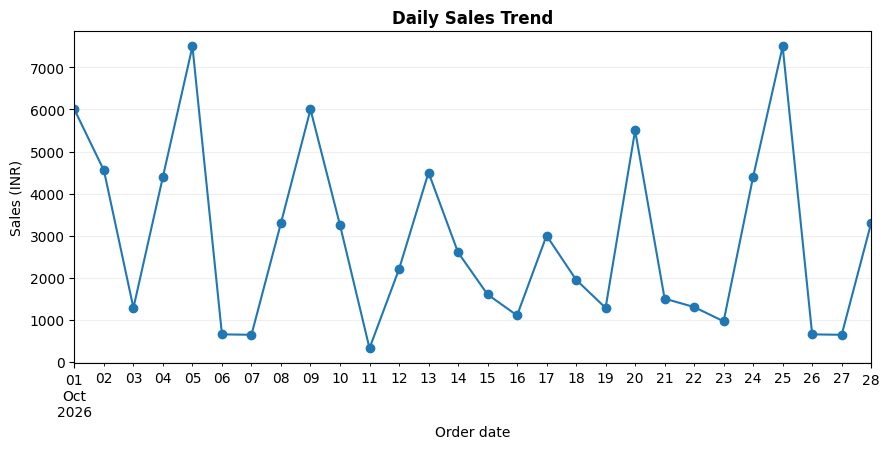

In [2]:
# Chart 1: Daily Sales Trend
fig, ax = plt.subplots(figsize=(9, 4.6))
daily=df.groupby("Order_Date")["Sales"].sum(); ax=daily.plot(kind="line",marker="o"); ax.set(xlabel="Order date",ylabel="Sales (INR)")
ax.set_title("Daily Sales Trend", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "01_daily_line.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 2: Sales by Category
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Compare category revenue; taller bars represent higher total sales.

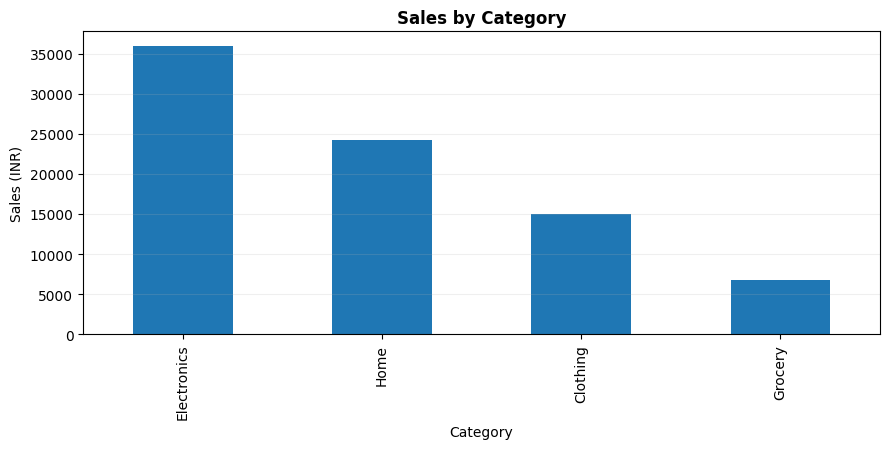

In [3]:
# Chart 2: Sales by Category
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("Category")["Sales"].sum().sort_values(ascending=False); ax=s.plot(kind="bar"); ax.set(xlabel="Category",ylabel="Sales (INR)")
ax.set_title("Sales by Category", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "02_category_bar.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 3: Order Sales Distribution
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Shows how frequently different order values occur.

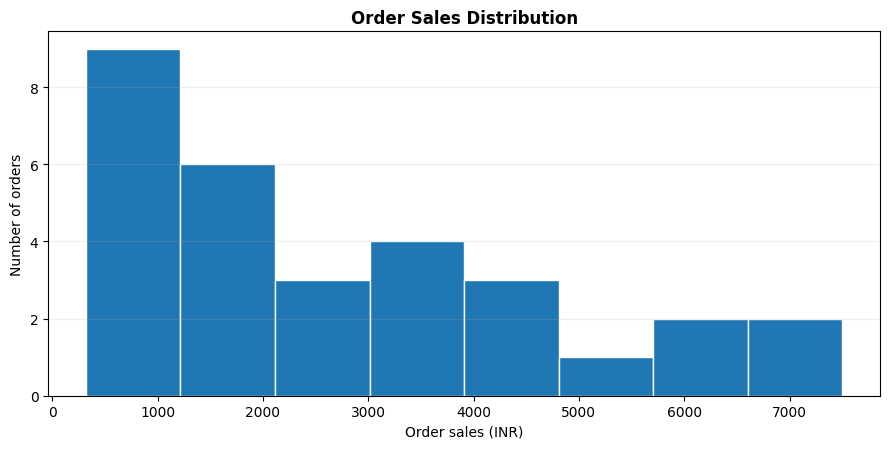

In [4]:
# Chart 3: Order Sales Distribution
fig, ax = plt.subplots(figsize=(9, 4.6))
ax=df["Sales"].plot(kind="hist",bins=8,edgecolor="white"); ax.set(xlabel="Order sales (INR)",ylabel="Number of orders")
ax.set_title("Order Sales Distribution", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "03_sales_hist.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 4: Quantity vs Sales
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Higher quantity does not always imply higher sales because unit prices differ.

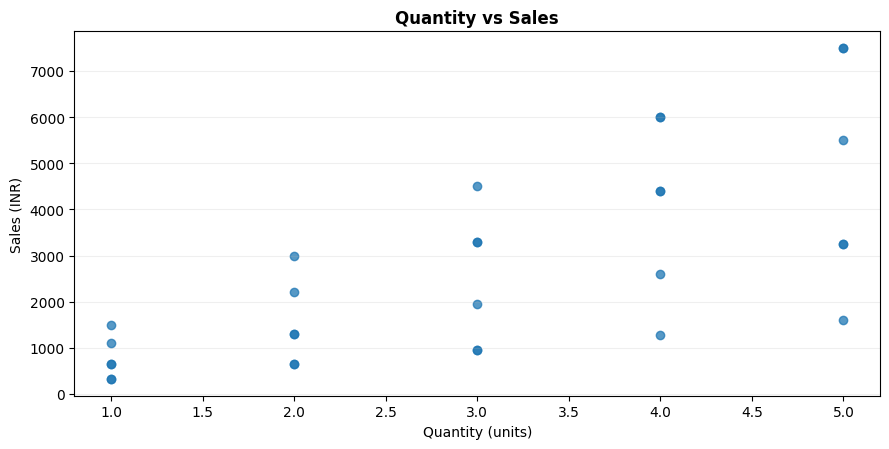

In [5]:
# Chart 4: Quantity vs Sales
fig, ax = plt.subplots(figsize=(9, 4.6))
ax=plt.gca(); ax.scatter(df["Quantity"],df["Sales"],alpha=.75); ax.set(xlabel="Quantity (units)",ylabel="Sales (INR)")
ax.set_title("Quantity vs Sales", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "04_quantity_scatter.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 5: Revenue Share by City
**Chart type:** pie.  
**Interpretation:** Shows each city’s share of total sales; pie charts have no Cartesian axes.

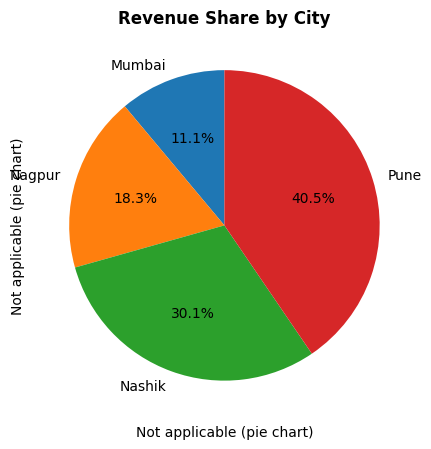

In [6]:
# Chart 5: Revenue Share by City
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("City")["Sales"].sum(); ax=plt.gca(); ax.pie(s,labels=s.index,autopct="%1.1f%%",startangle=90); ax.set(xlabel="Not applicable (pie chart)",ylabel="Not applicable (pie chart)")
ax.set_title("Revenue Share by City", fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "05_city_pie.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 6: Sales Spread by Category
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Boxes summarize median, quartiles and potential outliers for order sales.

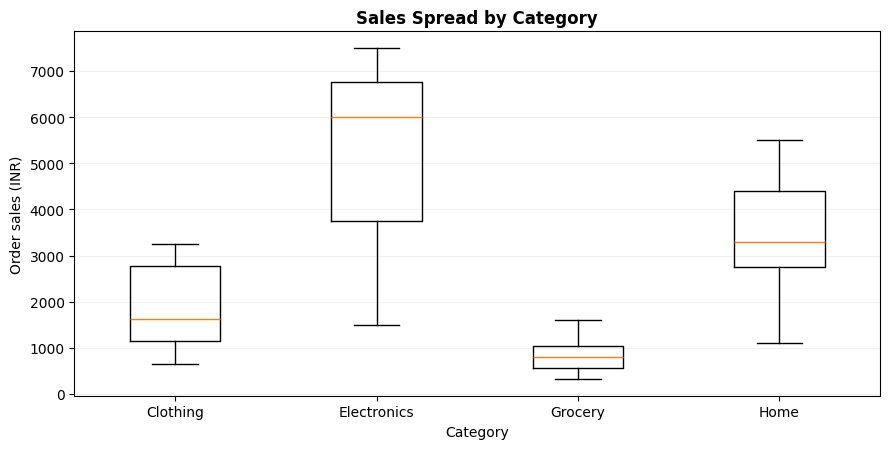

In [7]:
# Chart 6: Sales Spread by Category
fig, ax = plt.subplots(figsize=(9, 4.6))
cats=sorted(df.Category.unique()); ax=plt.gca(); ax.boxplot([df.loc[df.Category==c,"Sales"] for c in cats],tick_labels=cats); ax.set(xlabel="Category",ylabel="Order sales (INR)")
ax.set_title("Sales Spread by Category", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "06_category_box.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 7: Cumulative Sales Area
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Cumulative sales rise as transactions are added over time.

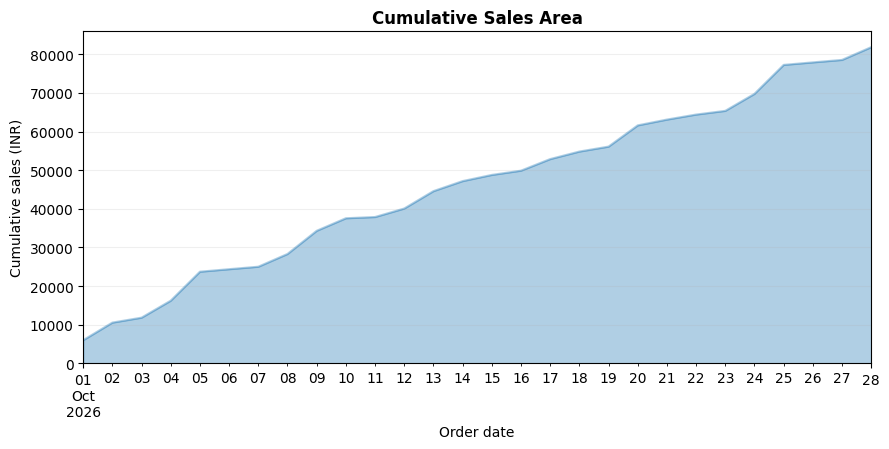

In [8]:
# Chart 7: Cumulative Sales Area
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("Order_Date")["Sales"].sum().cumsum(); ax=s.plot.area(alpha=.35); ax.set(xlabel="Order date",ylabel="Cumulative sales (INR)")
ax.set_title("Cumulative Sales Area", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "07_daily_area.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 8: Sales by City
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Compares geographic revenue without implying city population or demand.

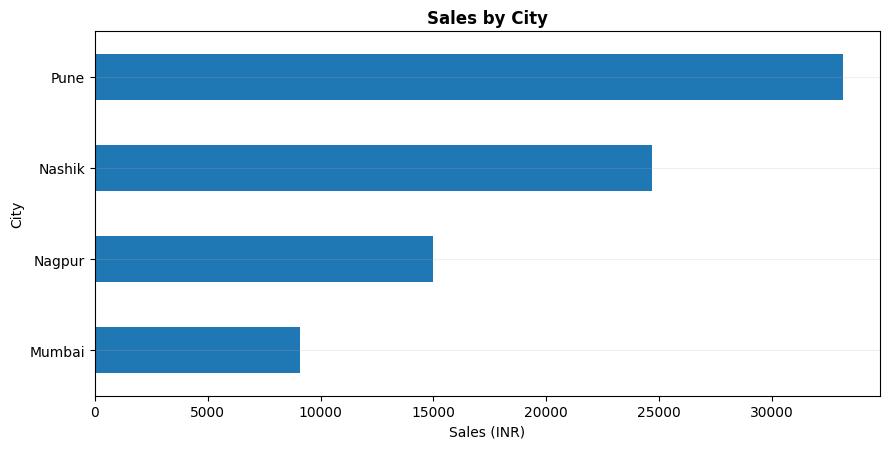

In [9]:
# Chart 8: Sales by City
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("City")["Sales"].sum().sort_values(); ax=s.plot(kind="barh"); ax.set(xlabel="Sales (INR)",ylabel="City")
ax.set_title("Sales by City", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "08_city_horizontal.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 9: Top Products by Revenue
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Ranks the five highest-revenue products in the sample.

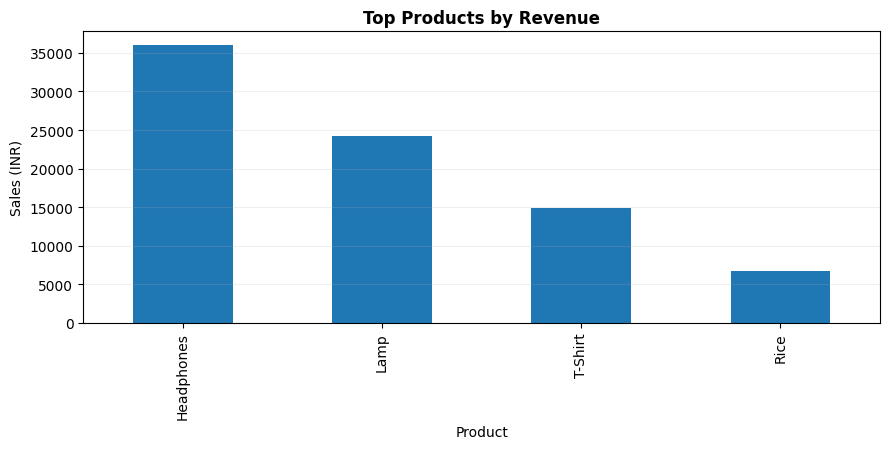

In [10]:
# Chart 9: Top Products by Revenue
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("Product")["Sales"].sum().nlargest(5); ax=s.plot(kind="bar"); ax.set(xlabel="Product",ylabel="Sales (INR)")
ax.set_title("Top Products by Revenue", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "09_product_bar.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 10: Customer Rating Distribution
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Uses non-missing ratings only; missing ratings are not interpreted as zero.

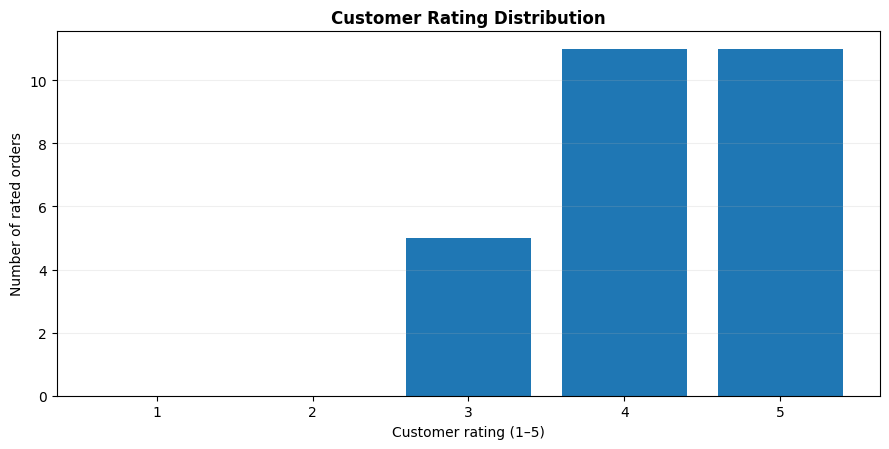

In [11]:
# Chart 10: Customer Rating Distribution
fig, ax = plt.subplots(figsize=(9, 4.6))
ax=df["Customer_Rating"].dropna().plot(kind="hist",bins=np.arange(.5,6.5,1),rwidth=.8); ax.set(xlabel="Customer rating (1–5)",ylabel="Number of rated orders")
ax.set_title("Customer Rating Distribution", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "10_rating_hist.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 11: Average Sales by Quantity
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Shows average order revenue at each quantity level, not a time trend.

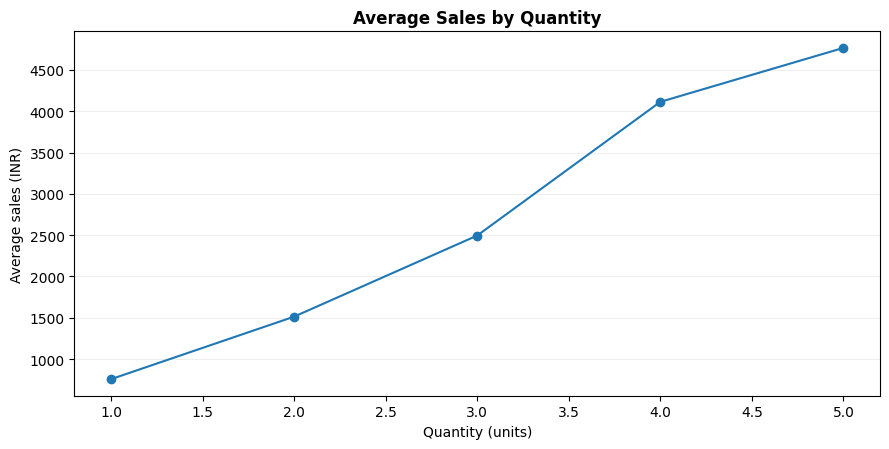

In [12]:
# Chart 11: Average Sales by Quantity
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("Quantity")["Sales"].mean(); ax=s.plot(kind="line",marker="o"); ax.set(xlabel="Quantity (units)",ylabel="Average sales (INR)")
ax.set_title("Average Sales by Quantity", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "11_quantity_line.png", dpi=140, bbox_inches="tight")
plt.show()

## Chart 12: Monthly Sales
**Chart type:** Matplotlib statistical / comparison chart.  
**Interpretation:** Summarizes revenue for months represented in the dataset only.

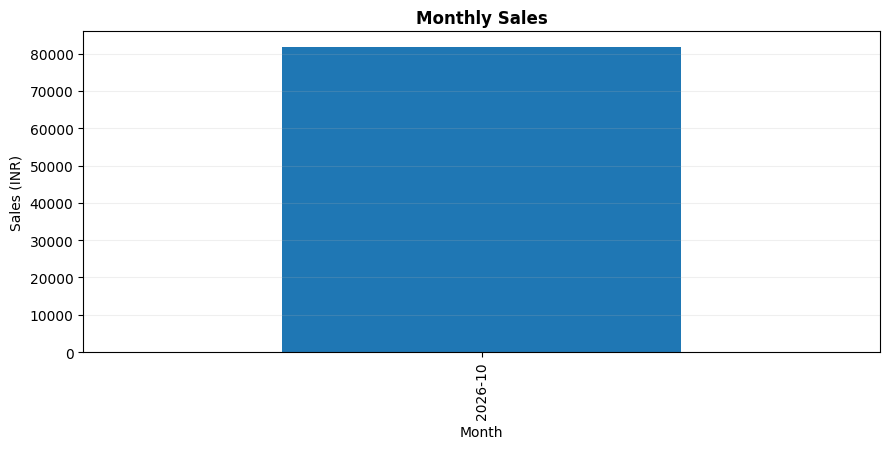

In [13]:
# Chart 12: Monthly Sales
fig, ax = plt.subplots(figsize=(9, 4.6))
s=df.groupby("Month")["Sales"].sum(); ax=s.plot(kind="bar"); ax.set(xlabel="Month",ylabel="Sales (INR)")
ax.set_title("Monthly Sales", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "12_month_bar.png", dpi=140, bbox_inches="tight")
plt.show()

## Findings and limitations
- The dataset is small and synthetic, so results are practice insights, not evidence about a real retailer.
- Grouped totals represent the included orders only.
- The pie chart uses slice labels and percentages instead of meaningful x/y axes.
- Three missing customer ratings are excluded from rating analysis.
- Some charts summarize the same sales data in different ways to demonstrate visual design.

**Proof:** Run All, verify 12 saved PNG charts in `Day11_Charts`, and capture VS Code screenshots of the notebook outputs.